# <font color="greenyellow" size="7"><b>YOLO</b></font>

<font color="greenyellow" size="5"><b>Detección de <i>Ochroma pyramidale</i> · cuaderno paso a paso</b></font>

Este cuaderno entrena el **YOLO26l-seg** de la tesis, paso a paso, con la misma receta de tu cuaderno Ultima_prueba_YOLO26: una tesela de 640 px centrada en cada polígono, corte espacial 70/30 y 150 épocas desde los pesos de COCO. Necesita GPU.

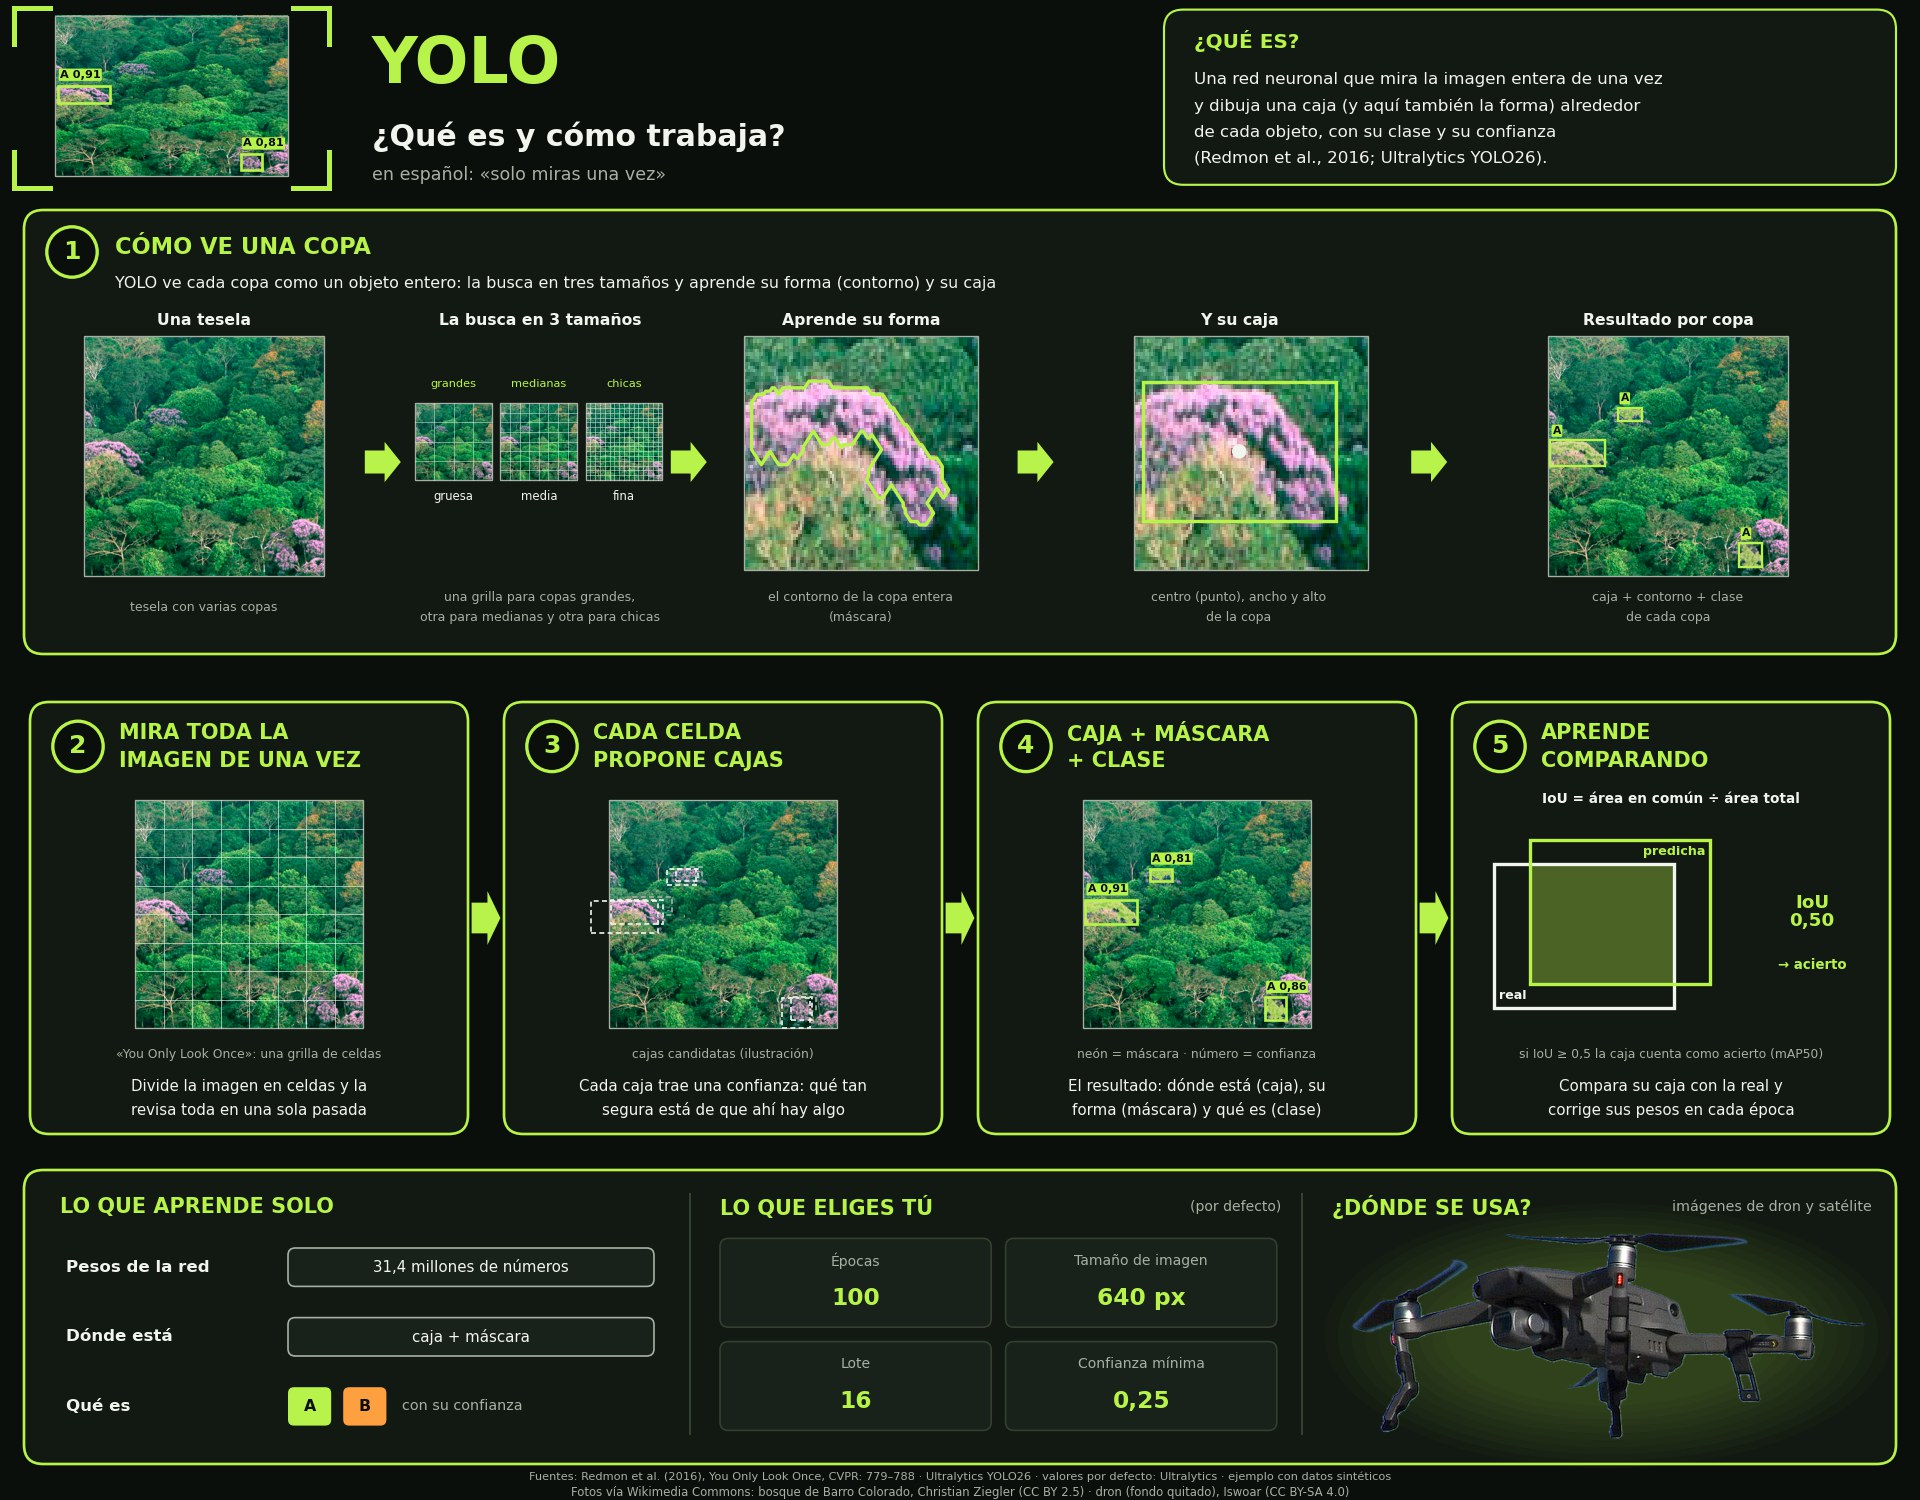

**Pasos:** **1** Conectar Drive y cargar las herramientas · **2** Rutas y parámetros · **3** Abrir el ortomosaico y ver tus polígonos · **4** Dividir: 70 % aprende, 30 % valida · **5** Cortar las teselas de 640 px · **6** Ver algunas teselas · **7** Entrenar YOLO26l-seg · **8** Validar en el 30 % · **9** Detectar en todo el ortomosaico · **10** Mapa final (tú eliges el estilo) · **11** Ortomosaico interactivo con barra de umbral · **12** Guardar las copas del umbral que elegiste

**Cómo usarlo:** corre las celdas en orden con ▶. Solo se cambia el **Paso 2** (rutas y parámetros); el resto ya está listo.

## <font color="greenyellow" size="6"><b>PASO 1 · Conectar Drive y cargar las herramientas</b></font>
**Para qué:** que Colab lea tus datos, instalar lo que necesita esta red y cargar las funciones de cada paso (`topa_pasos.py`).  
**Qué verás:** «Mounted at /content/drive». Antes de empezar: Entorno de ejecución → Cambiar tipo → GPU.

In [1]:
from google.colab import drive; drive.mount("/content/drive")
!pip install -q rasterio ultralytics
import sys; sys.path.append("/content/drive/MyDrive/PASO_A_PASO")
from topa_pasos import *
estilo_figuras(tam_letra=11, fuente="DejaVu Sans")     # letra de TODAS las figuras: tamaño y tipo
# los colores se escriben con su nombre: verde, rojo, amarillo, azul, negro… (para verlos todos: ver_colores())

Mounted at /content/drive


## <font color="greenyellow" size="6"><b>PASO 2 · Rutas y parámetros</b></font>
**Para qué:** decir dónde están tus datos y dónde se guarda lo que salga. Es lo único que se cambia.

In [2]:
ORTO = "/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/ortomosaico_TOPA.tif"
SHP = "/content/drive/MyDrive/SHP_3/SHP_topa.shp"
CAMPO, TOPA = "ESPECIE", "1"                                   # campo de especie y valor que es topa
SALIDA = "/content/drive/MyDrive/PASO_A_PASO/RESULTADOS_YOLO"     # aquí quedan el modelo y el mapa
DATASET = "/content/ds_topa_seg_7030"                         # teselas y etiquetas en formato YOLO (disco de Colab)

## <font color="greenyellow" size="6"><b>PASO 3 · Abrir el ortomosaico y ver tus polígonos</b></font>
**Para qué:** comprobar los datos y darle a cada polígono su clase de YOLO (0 = topa, 1 = otras).  
**Qué verás:** cuántos polígonos hay de cada clase y el mapa: verde topa, rojo otras especies.

In [3]:
src = abrir_orto(ORTO)
g = yolo_poligonos(SHP, src, CAMPO, TOPA)
ver_mapa(src, [capa(g[g.cls == 0], relleno="ninguno", borde="verde claro", etiqueta="topa", grosor=0.6),
               capa(g[g.cls == 1], relleno="ninguno", borde="rojo", etiqueta="otras especies", grosor=0.6)],
         titulo="Tus polígonos", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha")

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 4 · Dividir: 70 % aprende, 30 % valida</b></font>
**Para qué:** separar los polígonos con una línea: los del 70 % enseñan y los del 30 % sirven para medir.  
**Qué verás:** cuántos polígonos (y topas) quedan a cada lado y el mapa: celeste aprende, magenta valida.  
**Fuente:** corte espacial por el centro de cada polígono, como el RF: Htun et al. (2026), pp. 8 y 10. El 70/30 es del proyecto.

In [4]:
g, EJE, SV = yolo_corte(g, TRAIN_FRAC=0.70)
ver_mapa(src, capas_yolo(g, aprende="celeste", valida="magenta", relleno="ninguno", grosor=0.8),
         titulo="70 % aprende (celeste) · 30 % valida (magenta)", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha",
         linea=(EJE, SV), color_linea="rojo", grosor_linea=2)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 5 · Cortar las teselas de 640 px</b></font>
**Para qué:** hacer una imagen de 640 × 640 px centrada en cada polígono, con el contorno de las copas que caen dentro (así aprende YOLO).  
**Qué verás:** cuántas teselas salieron de cada lado y cuántas copas de topa y de otras llevan.  
**Fuente:** 640 px: Sengun et al. (2025) y Ultralytics. Estiramiento 2–98 % del color natural.

In [7]:
yolo_teselas(src, g, DATASET, TILE=640, RGB=(1, 2, 3))

aprende 506 teselas (topa 4906 / otras 259) · valida 209 teselas (topa 1403 / otras 129) · saltadas 0


'/content/ds_topa_seg_7030'

## <font color="greenyellow" size="6"><b>PASO 6 · Ver algunas teselas</b></font>
**Para qué:** comprobar que los contornos caen sobre las copas correctas.  
**Qué verás:** 6 teselas al azar: verde topa, rojo otras.

In [8]:
ver_teselas(DATASET, SPLIT="train", NVER=6)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 7 · Entrenar YOLO26l-seg</b></font>
**Para qué:** ajustar la red YOLO26l-seg (ya preentrenada en fotos comunes, COCO) para que reconozca la topa en tus teselas.  
**Qué verás:** cómo bajan los errores y sube el acierto en cada época. Tarda varias horas; en cada época el avance se copia a Drive.  
**Fuente:** pesos COCO: Sengun et al. (2025); 640 px y lote 16: Ultralytics; semilla 42: Sapkota y Karkee (2026). Las 150 épocas y la paciencia 150 son criterio de la tesis.

> Se guarda la mejor época (best.pt). En GPU el resultado puede variar un poco de una corrida a otra.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ds_topa_seg_7030/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=

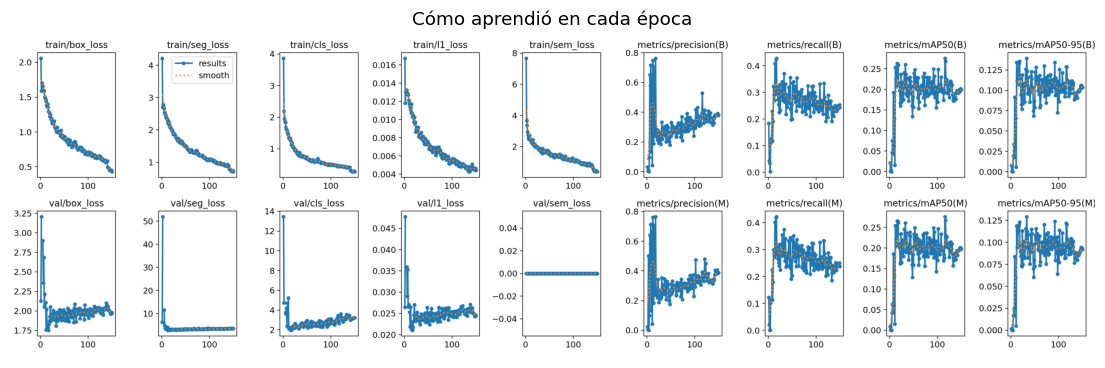

Modelo guardado (mejor época): /content/drive/MyDrive/PASO_A_PASO/RESULTADOS_YOLO/yolo_topa_seg_7030.pt


In [9]:
MODELO = entrenar_yolo(DATASET, SALIDA, NOMBRE="yolo_topa_seg_7030", MODELO_BASE="yolo26l-seg.pt", EPOCAS=150, TAM=640, LOTE=16, PACIENCIA=150, SEMILLA=42)

## <font color="greenyellow" size="6"><b>PASO 8 · Validar en el 30 %</b></font>
**Para qué:** medir qué tan bien encuentra las copas en las teselas que no usó para aprender.  
**Qué verás:** por clase: precisión (P), recuperación (R), mAP50 de cajas y de máscaras, aciertos y errores; la matriz de confusión y ejemplos.  
**Fuente:** métricas de Ultralytics con sus valores por defecto.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l-seg summary (fused): 204 layers, 27,905,298 parameters, 0 gradients, 139.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2763.8±882.4 MB/s, size: 246.9 KB)
val: Scanning /content/ds_topa_seg_7030/labels/val.cache... 209 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 67.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 1.0it/s 13.9s
                   all        209       1532       0.29      0.371       0.26       0.14      0.299      0.376      0.261      0.129
                  topa        169       1403      0.402      0.618      0.464      0.254      0.398      0.612      0.458      0.232
                 otras         53        129      0.178      0.124     0.0561     0.0254      0.201       0.14     0.0626      0.026
Speed: 2.4ms preprocess, 43.7ms

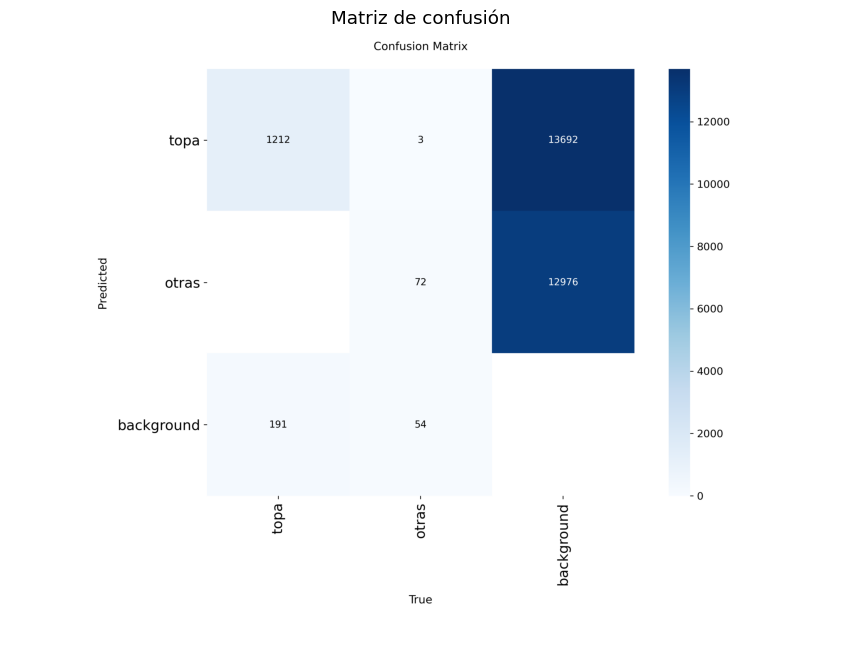

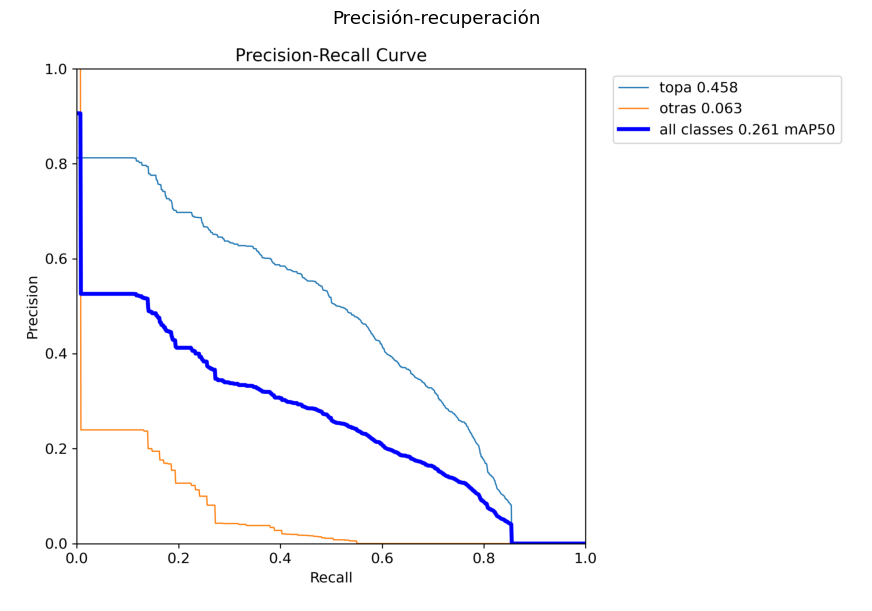

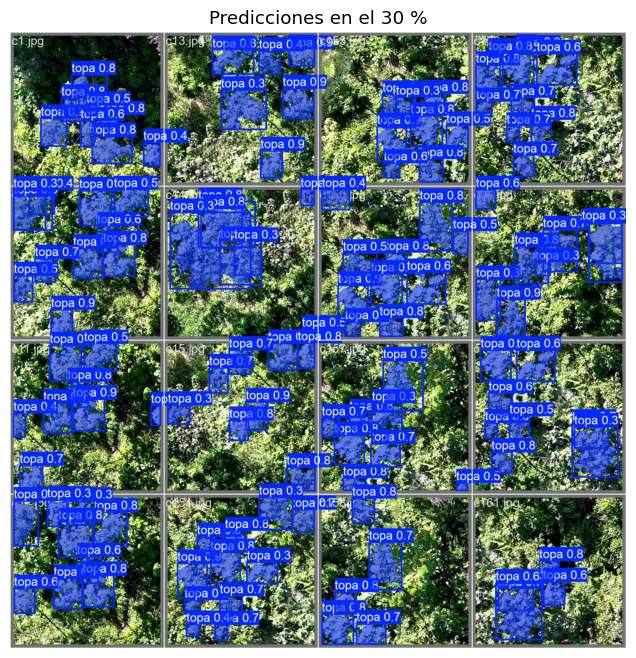

,P (caja),R (caja),mAP50 (caja),mAP50 (máscara),mAP50-95 (caja)
topa,0.402,0.618,0.464,0.458,0.254
otras,0.178,0.124,0.056,0.063,0.025


In [10]:
TAB = validar_yolo(MODELO, DATASET)
display(TAB)

## <font color="greenyellow" size="6"><b>PASO 9 · Detectar en todo el ortomosaico</b></font>
**Para qué:** correr el modelo en todo el ortomosaico y guardar sus copas de topa con su probabilidad.  
**Qué verás:** cuántas copas de topa encontró. Tarda varios minutos.  
**Fuente:** clase que da el modelo con umbral de decisión 0,50 (tutorial de Esri). Copa entera del watershed.

> Para usar el modelo de la tesis en vez del recién entrenado, antes de esta celda escribe: MODELO = "/content/drive/MyDrive/yolo_topa_seg_7030.pt"

In [11]:
TOP, SHP_TOPA = detectar(MODELO, ORTO, SALIDA, minimo=0.50)      # minimo = confianza más baja que se guarda (0,50 = la de la tesis)

Corriendo el modelo en todo el ortomosaico (puede tardar varios minutos)…
Modelo yolo_topa_seg_7030 · tipo YOLO · orto ortomosaico_TOPA · forma cajas
Modelo: yolo_topa_seg_7030.pt · clases ['topa', 'otras'] · bandas [1, 2, 3] · confianza y solape: 0.5
Orto a 1.84 cm: 12528×17318 px (preparado en 5 s) · YOLO recorre 36 franjas…
   franja 5/36 · 3 marcas · faltan ~2.2 min
   franja 10/36 · 11 marcas · faltan ~1.6 min
   franja 15/36 · 111 marcas · faltan ~1.3 min
   franja 20/36 · 288 marcas · faltan ~1.0 min
   franja 25/36 · 544 marcas · faltan ~0.7 min
   franja 30/36 · 552 marcas · faltan ~0.4 min
   franja 35/36 · 557 marcas · faltan ~0.1 min
   duplicados (se solapan más de 0.5, como el tutorial de Esri): se quitan 17 de 557 detecciones
   YOLO marcó 516 topas y 24 otras en 130 s
Forma «copa entera»: uso las 1419 copas de todo ortomosaico_TOPA ya hechas (/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/copas_entera_ortomosaico_TOPA_d3_a22-79.25.gpkg)
   516 topas de

## <font color="greenyellow" size="6"><b>PASO 10 · Mapa final (tú eliges el estilo)</b></font>
**Para qué:** dibujar el mapa de presentación. Cambia los valores para elegir el título, las letras, los colores, la leyenda y lo demás.  
**Qué verás:** el mapa con marco, coordenadas en los 4 lados, escala, norte y leyenda; queda guardado en SALIDA. Si solo cambias el estilo, corre esta celda otra vez (no hace falta detectar de nuevo).

> Colores: escríbelos con su nombre en español (verde, rojo, rojo vivo, amarillo, naranja, azul, celeste, morado, rosado, marrón, gris, negro, blanco…) o en inglés (green, red, black…); «ninguno» = sin relleno. Para ver todos los colores: ver_colores(). Lugar de la leyenda: «arriba derecha», «arriba izquierda», «abajo derecha», «abajo izquierda» o «centro». Transparencia: de 0 (invisible) a 1 (opaco).

In [16]:
SHP_TOPA = f"{SALIDA}/topa_yolo_topa_seg_7030_ortomosaico_TOPA_ws_esri.shp"   # tus copas detectadas en el paso 9
TOP = gpd.read_file(SHP_TOPA)
mapa_final(ORTO, TOP, "YOLO", SALIDA,
           titulo="Detección de", especie="Ochroma pyramidale", tam_titulo=13,
           relleno="rojo", transparencia=0.45, borde="amarillo", grosor=0.7,
           titulo_leyenda=None, tam_leyenda=9, pos_leyenda="abajo derecha",
           norte=True, tam_norte=0.6, pos_norte="arriba derecha", fondo_norte="blanco",
           escala=True, largo_escala=None, tramos_escala=4, tam_escala=1.0, pos_escala="abajo izquierda",
           coordenadas=True, tam_coord=8, cada_coord=None, lados_coord="cuatro", sistema=True,
           tam_letra=8, color_marco="negro", ancho=9, dpi=300)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 11 · Ortomosaico interactivo con barra de umbral</b></font>
**Para qué:** mover y acercar el ortomosaico con el ratón y mover la barra de umbral: se ven las copas con probabilidad mayor que el umbral y cuántas son.  
**Qué verás:** la página interactiva. En 0,50 marca las mismas copas que el mapa final. Al pasar el ratón sobre una copa se ve su probabilidad; la otra barra aclara el ortomosaico.

> En YOLO la barra empieza en la confianza mínima del paso «Detectar» (0,50). Para verla desde 0,10, detecta otra vez en otra carpeta: TOP_I, SHP_I = detectar(MODELO, ORTO, f"{SALIDA}/interactivo", minimo=0.10) y usa SHP_I en esta celda.

In [13]:
mapa_interactivo(ORTO, SHP_TOPA, umbral=0.50, titulo="Detección de Ochroma pyramidale",
                 relleno="rojo vivo", borde="blanco", transparencia=0.40, grosor=1.2, tam_letra=14, alto=650)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 12 · Guardar las copas del umbral que elegiste</b></font>
**Para qué:** guardar en un SHP (para ArcGIS o QGIS) las copas con probabilidad mayor que el umbral que elegiste en la barra.  
**Qué verás:** cuántas copas pasaron el umbral y dónde quedó el SHP.

> Para el mapa de presentación con ese umbral: mapa_final(ORTO, TOP_U, "YOLO", SALIDA, titulo="Detección de", relleno="rojo")

In [ ]:
TOP_U, SHP_U = guardar_umbral(SHP_TOPA, umbral=0.50)      # pon aquí el umbral que elegiste en la barra